# Labels and subjects

Compare label counts and variation across tasks. Set `COHORTS` to select years.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.eda.io import load_tasks, cohort_tables

COHORTS = None  # Discover all years; use ["1year"] or ["2year", "3year"] to restrict.
tables = load_tasks(ROOT / "data", cohorts=COHORTS)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
print("Loaded task files by cohort:", {c: len(g) for c, g in cohort_tables(tables).items()})


Loaded task files by cohort: {'1year': 21, '2year': 21, '3year': 18}


In [2]:
from src.eda.labels import (label_counts, rare_class_flags, subject_label_matrix,
                            subject_label_patterns, task_label_agreement)
from src.eda.plotting import plot_label_distributions, plot_class_counts, plot_agreement

counts = label_counts(tables)
rare = rare_class_flags(counts)
display(counts.groupby(["cohort", "label_kind", "label"], sort=False)["count"].sum().to_frame("raw_rows"))
display(counts.loc[counts.label_kind.eq("valid"), [
    "cohort", "task", "label", "count", "raw_total", "eligible_total", "raw_proportion", "eligible_proportion"
]].head(12))


raw_rows
cohort label_kind label          
1year  valid      0           370
                  1           809
                  2          1188
       unresolved -1          568
2year  valid      0           386
                  1           849
                  2          1263
       unresolved -1          547
3year  valid      0           364
                  1           718
                  2          1041
       unresolved -1          487

,cohort,task,label,count,raw_total,eligible_total,raw_proportion,eligible_proportion
0,1year,Task_1,0,2,140,113,0.014286,0.017699
1,1year,Task_1,1,17,140,113,0.121429,0.150442
2,1year,Task_1,2,94,140,113,0.671429,0.831858
4,1year,Task_2,0,8,140,113,0.057143,0.070796
5,1year,Task_2,1,48,140,113,0.342857,0.424779
6,1year,Task_2,2,57,140,113,0.407143,0.504425
8,1year,Task_3,0,0,140,113,0.000000,0.000000
9,1year,Task_3,1,14,140,113,0.100000,0.123894
10,1year,Task_3,2,99,140,113,0.707143,0.876106
12,1year,Task_4,0,0,140,113,0.000000,0.000000


Stacked bars include every label; count heatmaps use `{0, 1, 2}`. Labels are nominal. `counts` gives proportions relative to raw and eligible rows.

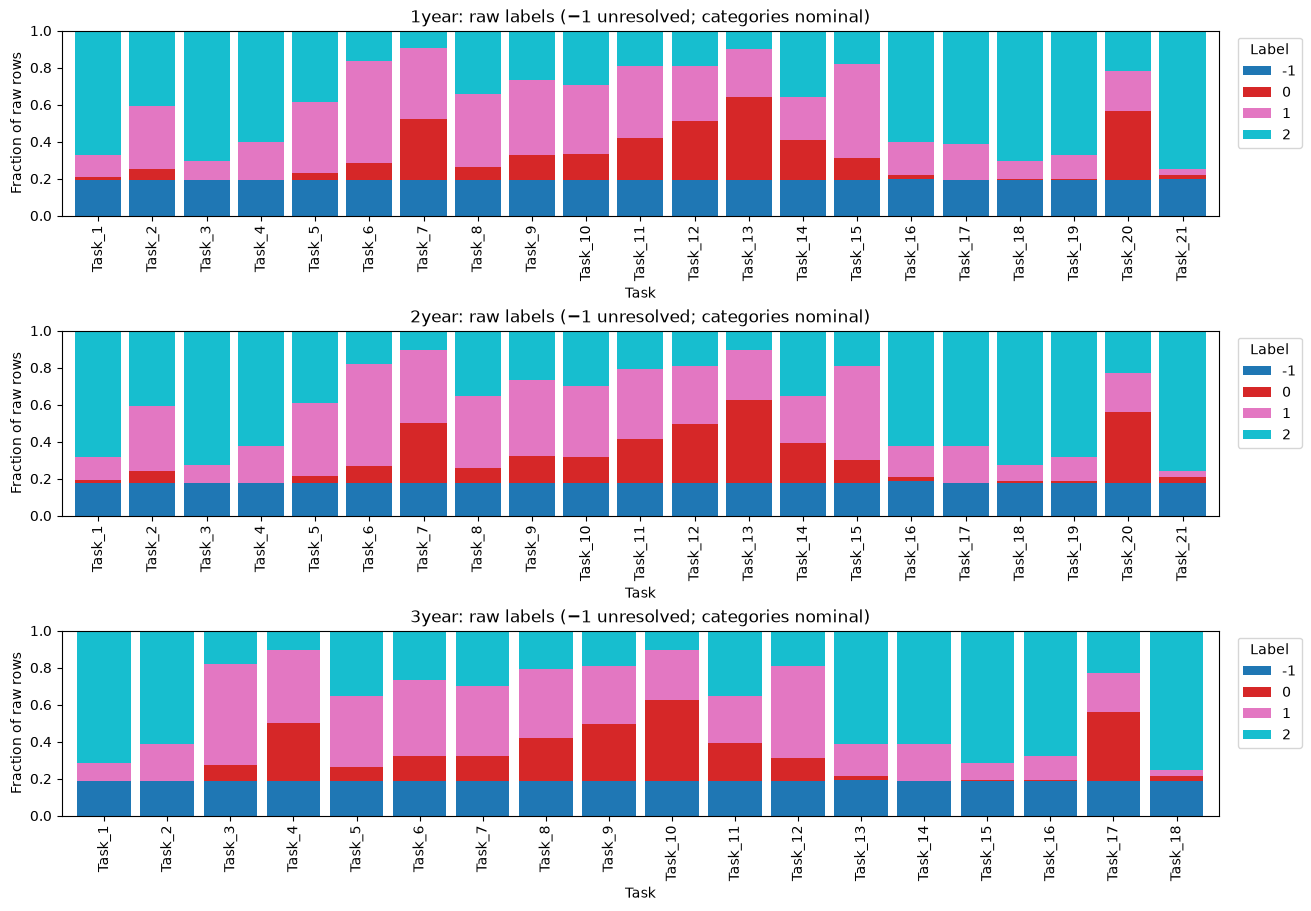

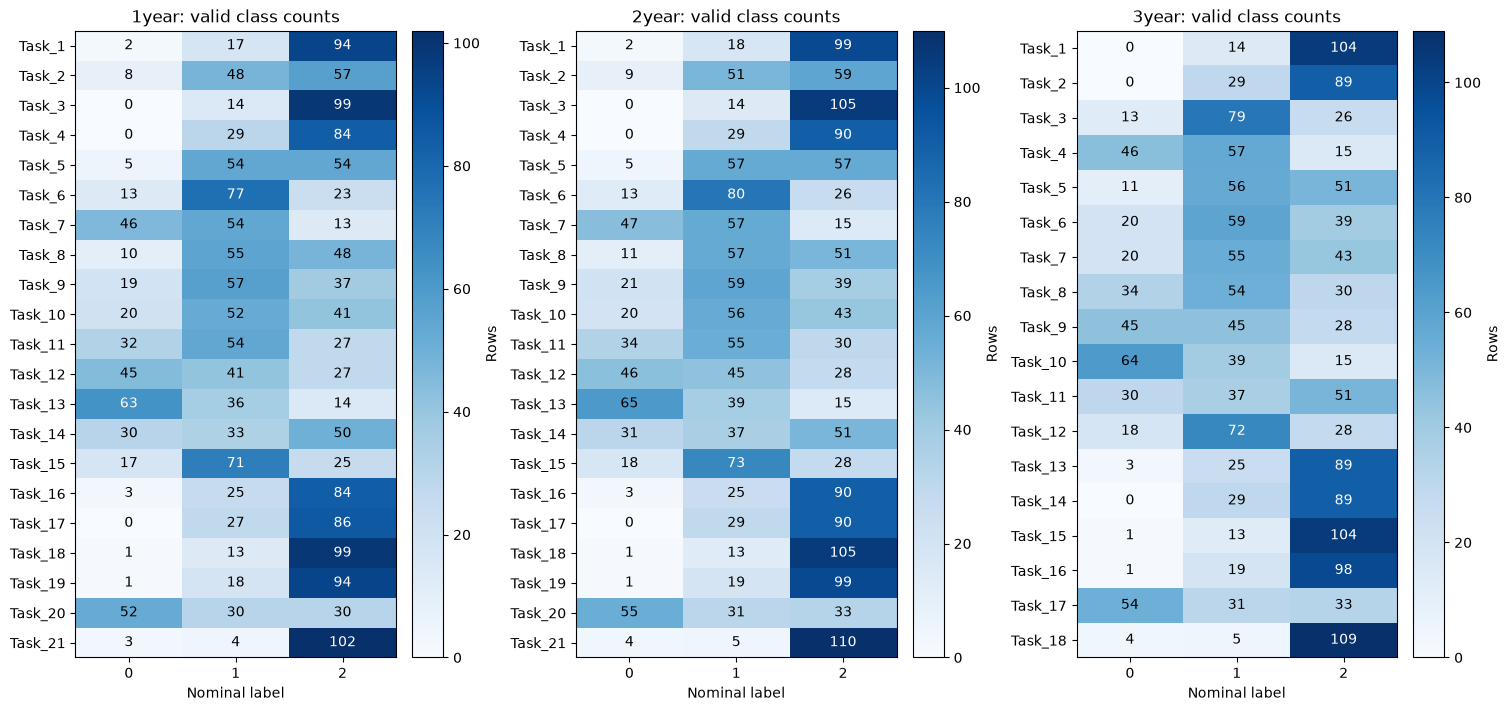

In [3]:
plot_label_distributions(counts);
plt.show()
plot_class_counts(counts);
plt.show()

In [4]:
patterns, agreements, join_warnings = [], [], []
label_matrices = {}  # Private in-memory subject-level objects; never displayed or exported.
for cohort, group in cohort_tables(tables).items():
    try:
        matrix = subject_label_matrix(group)
    except (ValueError, KeyError) as error:
        join_warnings.append({"cohort": cohort, "reason": str(error)})
        continue
    label_matrices[cohort] = matrix
    patterns.append(subject_label_patterns(matrix).assign(cohort=cohort))
    agreements.append(task_label_agreement(matrix).assign(cohort=cohort))
if patterns:
    display(pd.concat(patterns, ignore_index=True))
if join_warnings:
    display(pd.DataFrame(join_warnings))


,distinct_valid_labels,subjects,cohort
0,0,27,1year
1,1,0,1year
2,2,13,1year
3,3,100,1year
4,0,26,2year
5,1,0,2year
6,2,13,2year
7,3,106,2year
8,0,27,3year
9,1,0,3year


Agreement uses subjects with valid labels in both tasks. The second heatmap gives each pair's eligible count.

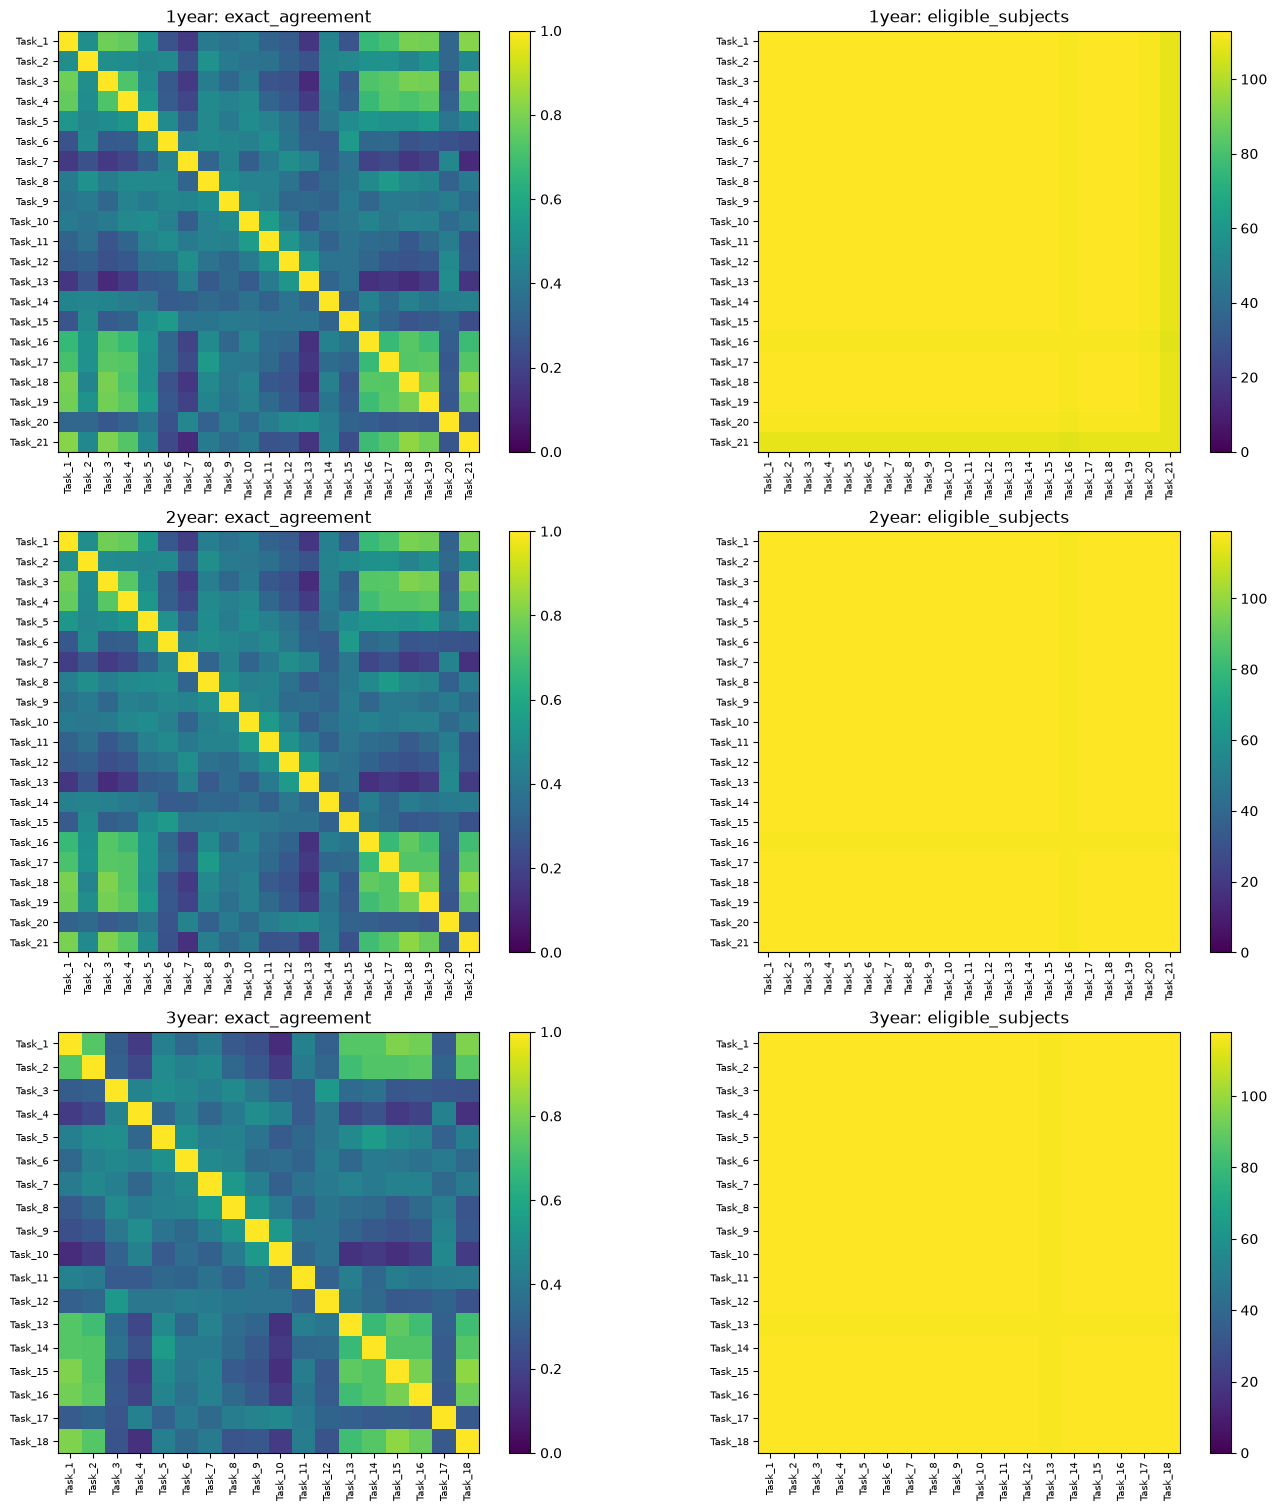

,min_pairwise_n,max_pairwise_n
cohort,,
1year,108,113
2year,118,119
3year,117,118


In [5]:
if agreements:
    agreement = pd.concat(agreements, ignore_index=True)
    plot_agreement(agreement)
    plt.show()
    display(agreement.groupby("cohort").agg(min_pairwise_n=("eligible_subjects", "min"),
                                           max_pairwise_n=("eligible_subjects", "max")))


In [6]:
display(rare.loc[rare.support.ne("at_least_threshold")])
task_imbalance = rare.groupby(["cohort", "task"], sort=False).agg(
    smallest_class_count=("smallest_class_count", "first"),
    majority_prevalence=("majority_prevalence", "first"),
)
display(task_imbalance.groupby("cohort").agg(
    worst_minority_count=("smallest_class_count", "min"),
    largest_majority_prevalence=("majority_prevalence", "max"),
))


,cohort,task,label,count,support,smallest_class_count,majority_prevalence,warning_threshold
0,1year,Task_1,0,2,very_few,2,0.831858,5
8,1year,Task_3,0,0,absent,0,0.876106,5
12,1year,Task_4,0,0,absent,0,0.743363,5
60,1year,Task_16,0,3,very_few,3,0.750000,5
64,1year,Task_17,0,0,absent,0,0.761062,5
68,1year,Task_18,0,1,singleton,1,0.876106,5
72,1year,Task_19,0,1,singleton,1,0.831858,5
80,1year,Task_21,0,3,very_few,3,0.935780,5
81,1year,Task_21,1,4,very_few,3,0.935780,5
84,2year,Task_1,0,2,very_few,2,0.831933,5


,worst_minority_count,largest_majority_prevalence
cohort,,
1year,0,0.935780
2year,0,0.924370
3year,0,0.923729


Labels can vary by task. Row totals count task records, not distinct children. Rare-class flags describe support without establishing statistical adequacy.